In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

mean = (0.5, 0.5, 0.5)
std = (0.5, 0.5, 0.5)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=train_transform
)

test_dataset = datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=test_transform
)

Using device: cuda


Размерности данных:
Количество тренировочных примеров =  50000
Количество тестовых примеров =  10000
Форма одного изображения =  torch.Size([3, 32, 32])
Форма всех меток =  torch.Size([128])
Демонстрация изображений и меток классов для подтверждения корректности загрузки:


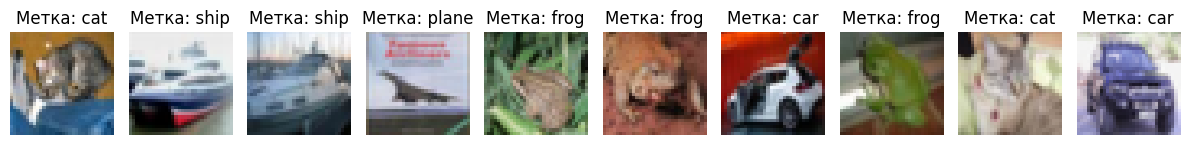

In [ ]:
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

images, labels = next(iter(test_loader))

print("Размерности данных:")
print("Количество тренировочных примеров = ", len(train_dataset) )
print("Количество тестовых примеров = ", len(test_dataset))
print("Форма одного изображения = ", images[0].shape)
print("Форма всех меток в пачке = ", labels.shape)

print("Демонстрация изображений и меток классов для подтверждения корректности загрузки:")
fig, axes = plt.subplots(1, 10, figsize=(12, 3))
for i in range(10):
    ax = axes[i]
    img = images[i].numpy().transpose(1, 2, 0)
    img = np.clip(img * std + mean, 0, 1)
    ax.imshow(img)
    ax.set_title(f'Метка: {classes[labels[i].item()]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [3]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(64)
        self.conv2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)
        self.pool2 = nn.MaxPool2d(2, 2)

        self.conv5 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn5 = nn.BatchNorm2d(256)
        self.conv6 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.bn6 = nn.BatchNorm2d(256)
        self.pool3 = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(256 * 4 * 4, 512)
        self.dropout1 = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, 10)

    def forward(self, X):
        X = F.relu(self.bn1(self.conv1(X)))
        X = F.relu(self.bn2(self.conv2(X)))
        X = self.pool1(X)

        X = F.relu(self.bn3(self.conv3(X)))
        X = F.relu(self.bn4(self.conv4(X)))
        X = self.pool2(X)

        X = F.relu(self.bn5(self.conv5(X)))
        X = F.relu(self.bn6(self.conv6(X)))
        X = self.pool3(X)

        X = X.view(-1, 256 * 4 * 4)
        X = F.relu(self.fc1(X))
        X = self.dropout1(X)
        X = self.fc2(X)

        return X

In [4]:
model = CNN().to(device)
print(model)

error_function = nn.CrossEntropyLoss()
update_parameters = optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4)
learning_rate = optim.lr_scheduler.StepLR(update_parameters, step_size=12, gamma=0.2)

CNN(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv5): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn5): BatchNorm2d(256, eps=1e

In [5]:
import time
epochs = 25
train_classification_errors = []

for epoch in range(epochs):
    start_time = time.time()

    model.train()
    train_error = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        update_parameters.zero_grad()

        outputs = model(inputs)
        error = error_function(outputs, labels)

        error.backward()
        update_parameters.step()

        train_error += error.item()
        predicted = torch.argmax(outputs, dim=1)
        train_total += labels.shape[0]
        train_correct += torch.sum(predicted == labels).item()

    train_classification_error = train_error / len(train_loader)
    train_accuracy = train_correct / train_total

    train_classification_errors.append(train_classification_error)

    epoch_time = time.time() - start_time
    print(f"Эпоха {epoch + 1:2d}/{epochs} | "
          f"Ошибка классификации: {train_classification_error:.4f} | "
          f"Точность: {train_accuracy * 100:.2f}% | "
          f"Время: {epoch_time:.2f}с")

    learning_rate.step()

Эпоха  1/25 | Ошибка классификации: 1.8774 | Точность: 28.39% | Время: 17.69с
Эпоха  2/25 | Ошибка классификации: 1.4209 | Точность: 47.69% | Время: 18.28с
Эпоха  3/25 | Ошибка классификации: 1.1374 | Точность: 60.30% | Время: 17.03с
Эпоха  4/25 | Ошибка классификации: 0.9432 | Точность: 67.47% | Время: 17.00с
Эпоха  5/25 | Ошибка классификации: 0.8100 | Точность: 72.94% | Время: 17.99с
Эпоха  6/25 | Ошибка классификации: 0.7145 | Точность: 76.00% | Время: 17.17с
Эпоха  7/25 | Ошибка классификации: 0.6373 | Точность: 78.82% | Время: 17.02с
Эпоха  8/25 | Ошибка классификации: 0.5887 | Точность: 80.60% | Время: 16.93с
Эпоха  9/25 | Ошибка классификации: 0.5513 | Точность: 81.60% | Время: 16.99с
Эпоха 10/25 | Ошибка классификации: 0.5136 | Точность: 83.15% | Время: 17.66с
Эпоха 11/25 | Ошибка классификации: 0.4846 | Точность: 84.00% | Время: 17.63с
Эпоха 12/25 | Ошибка классификации: 0.4618 | Точность: 84.61% | Время: 17.09с
Эпоха 13/25 | Ошибка классификации: 0.3161 | Точность: 89.60% | 

In [6]:
model.eval()
start_time = time.time()
test_error = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        error = error_function(outputs, labels)

        test_error += error.item()
        predicted = torch.argmax(outputs, dim=1)
        test_total += labels.shape[0]
        test_correct += torch.sum(predicted == labels).item()

final_test_error = test_error / len(test_loader)
final_accuracy = test_correct / test_total

test_time = time.time() - start_time
print("Результаты:")
print(f"Ошибка классификации на тестовом наборе: {final_test_error:.4f}")
print(f"Точность на тестовом наборе: {final_accuracy * 100:.2f}%")
print(f"Время: {test_time:.2f}с")


Результаты:
Ошибка классификации на тестовом наборе: 0.2889
Точность на тестовом наборе: 91.01%
Время: 1.75с


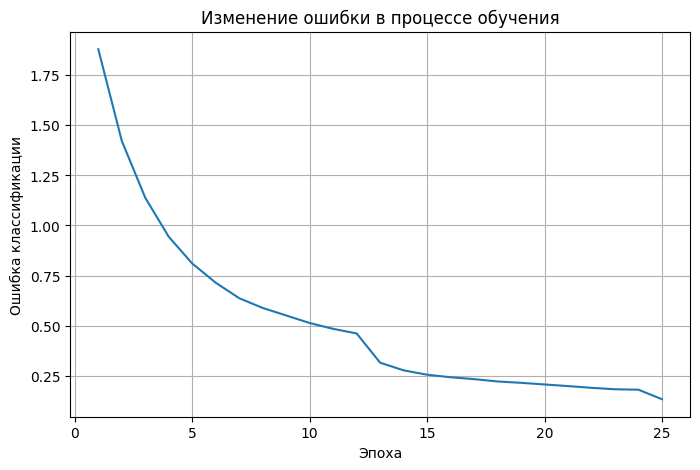

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_classification_errors)
plt.xlabel('Эпоха')
plt.ylabel('Ошибка классификации')
plt.title('Изменение ошибки в процессе обучения')
plt.grid(True)
plt.show()
